# Sequential experiment notebook

Read the numbered folders in order. Each README explains **what changed, implementation, results and interpretation**, with links to the original evidence. `Experiment_Log.ipynb` presents the same tables with saved outputs; no rerunning training is required to read it. `runs.json` is the machine-readable registry.

Quantization reduces numerical precision and weight storage. Channel pruning physically removes parts of the network. Recovery trains a compressed model to restore accuracy. Device compilation prepares it for a particular runtime.

Two accuracy protocols exist: the historical 500-image pilot and the current 27,000-image training-set evaluation. They are separate tables. Remote runs retain the historical 32-image numerical check and now add a labelled 1,000-image balanced diagnostic subset. That subset excludes 512 calibration images but is not held-out generalization or full-dataset accuracy. All model changes still start from the supplied student.

**Current saved winner:** [resize192_head_ce_w16](../best_models/resize192_head_ce_w16_e391533162d7/README.md). The versioned folder contains inference ONNX, recovered training weights, recipe, checksums and metrics. Older winners stay preserved. [Saving future winners](../docs/model_preservation.md).



In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display
project = Path.cwd()
if not (project / "edgeprep").exists(): project = project.parent
registry = json.loads((project / "experiments/runs.json").read_text())
display(pd.DataFrame([{k:r.get(k) for k in ["name","phase","status"]} for r in registry["records"]]))

,name,phase,status
0,baseline,historical_pilot,completed
1,qdq_s8,historical_pilot,completed
2,qdq_u8,historical_pilot,completed
3,qdq_s8_256,historical_pilot,completed
4,qdq_percentile,historical_pilot,completed
5,qdq_protected,historical_pilot,completed
6,qdq_pointwise,historical_pilot,completed
7,prune05,historical_pilot,completed
8,prune10,historical_pilot,completed
9,expansion05,historical_pilot,completed


# 01. Original models and dataset

Verified supplied MobileNetV2 and optional ResNet50, exact safe checkpoint loading, fixed 224 input, all 27,000 EuroSAT files and preprocessing. MobileNetV2 has 2,236,682 parameters; ResNet50 is the teacher, never the denominator.



# 02. Historical compression and short recovery

Before the organizer clarification, 13 variants were screened on 500 images from a provisional split. The table follows the experimental progression, not reconstructed timestamps. Full quantization, selective quantization, physical pruning, and short CE/KD recovery are different operations. CE/KD used only 500 training images for one epoch. These rows cannot be mixed with current all-data ratios.



In [2]:
rows = [r for r in registry["records"] if r["phase"] == 'historical_pilot' and r["name"] in ['baseline', 'qdq_s8', 'qdq_u8', 'qdq_s8_256', 'qdq_percentile', 'qdq_protected', 'qdq_pointwise', 'prune05', 'prune10', 'expansion05', 'expansion10', 'expansion05_ce', 'expansion05_kd']]
display(pd.DataFrame([{k:r.get(k) for k in ['label', 'accuracy_pct', 'worst_recall_pct', 'size_mib', 'median_cpu_4t_ms', 'estimated_cpu_4t_j', 'examples']} for r in rows]).round(4))

,label,accuracy_pct,worst_recall_pct,size_mib,median_cpu_4t_ms,estimated_cpu_4t_j,examples
0,Unchanged FP32 student,99.2,96.0,8.5063,2.1668,None,500
1,"Full INT8, signed / MinMax 128",92.6,66.0,2.5256,5.6622,None,500
2,"Full INT8, unsigned / MinMax 128",91.4,58.0,2.5414,4.3796,None,500
3,Full INT8 / MinMax 256,91.0,66.0,2.5257,5.2509,None,500
4,Full INT8 / Percentile 256,96.2,80.0,2.5255,5.7884,None,500
5,INT8 with first/last/head protected,96.0,90.0,3.7159,6.0622,None,500
6,Selective INT8 / MinMax 256,98.4,94.0,3.7720,5.3334,None,500
7,Uniform channel pruning 5%,16.0,0.0,7.6219,1.8400,None,500
8,Uniform channel pruning 10%,17.2,0.0,6.9353,1.6972,None,500
9,Expansion-only pruning 5%,83.2,46.0,8.1381,2.6330,None,500


# 03. Our current unchanged-student baseline

After the organizer clarified all-data training and our own laptop reference, evaluated the unchanged student on all 27,000 images. This is training-set accuracy. Exported FP32 ONNX and measured serial CPU runtime/RAM/estimated energy. No recovery or retraining. The table can display newer matched three-repetition timings; baseline_metrics.json preserves the original 20-second reference measurement.



In [3]:
rows = [r for r in registry["records"] if r["phase"] == 'current_all_data' and r["name"] in ['baseline']]
display(pd.DataFrame([{k:r.get(k) for k in ['label', 'accuracy_pct', 'worst_recall_pct', 'size_mib', 'median_cpu_4t_ms', 'estimated_cpu_4t_j', 'examples']} for r in rows]).round(4))

,label,accuracy_pct,worst_recall_pct,size_mib,median_cpu_4t_ms,estimated_cpu_4t_j,examples
0,Unchanged FP32 student,99.163,95.84,8.5063,2.7892,0.0549,27000


# 04. Selective INT8 with 256 MinMax samples

Quantized pointwise convolutions while preserving first/last layers, classifier and depthwise convolutions in FP32. Same learned parameters; smaller weight storage. Calibrated 256 balanced samples and evaluated all 27,000. Smaller does not mean faster: this graph regressed on our laptop CPU.



In [4]:
rows = [r for r in registry["records"] if r["phase"] == 'current_all_data' and r["name"] in ['qdq_pointwise']]
display(pd.DataFrame([{k:r.get(k) for k in ['label', 'accuracy_pct', 'worst_recall_pct', 'size_mib', 'median_cpu_4t_ms', 'estimated_cpu_4t_j', 'examples']} for r in rows]).round(4))

,label,accuracy_pct,worst_recall_pct,size_mib,median_cpu_4t_ms,estimated_cpu_4t_j,examples
0,Selective INT8 / MinMax 256,98.4111,95.4333,3.772,5.1842,0.1192,27000


# 05. Selective INT8 with 512 Percentile samples

Same selective precision pattern, now Percentile calibration and 512 balanced samples. This changes two knobs together; it screens a configuration but does not isolate the benefit of either algorithm or sample count. Full-data evaluation and fresh runtime measurements recorded when present.



In [5]:
rows = [r for r in registry["records"] if r["phase"] == 'current_all_data' and r["name"] in ['qdq_percentile512']]
display(pd.DataFrame([{k:r.get(k) for k in ['label', 'accuracy_pct', 'worst_recall_pct', 'size_mib', 'median_cpu_4t_ms', 'estimated_cpu_4t_j', 'examples']} for r in rows]).round(4))

,label,accuracy_pct,worst_recall_pct,size_mib,median_cpu_4t_ms,estimated_cpu_4t_j,examples
0,Selective INT8 / Percentile 512,98.8037,95.36,3.7719,5.5206,0.1322,27000


# 06. Real-device CPU/NPU deployment

Authenticated using the ignored .env key. Retrieved 78 catalogue entries. S24 CPU and NPU exploration, plus RB3 Hub-native W8A8 compilation. First S24 NPU inference failed because compute_unit and an explicit provider were both specified; the retry removes compute_unit from inference options. Remote 32-image agreement is a smoke check. New dataset_accuracy.json files measure labelled accuracy on 1,000 balanced images, separately from all-data laptop accuracy. Preserve failures alongside successful runs.



In [6]:
rows = [r for r in registry["records"] if r["phase"] == 'remote_exploration' and r["name"] in ['s24_cpu_fp32', 's24_npu_float', 's24_npu_float_retry', 'rb3_npu_w8a8', 'rb3_onnx_npu_w8a8', 'rb3_onnx_npu_w8a16', 's24_npu_float_retry_balanced', 's24_npu_float_retry_power_saver', 'rb3_onnx_npu_w8a8_balanced', 'rb3_onnx_npu_w8a8_power_saver']]
display(pd.DataFrame([{k:r.get(k) for k in ['name', 'status', 'device', 'precision', 'performance_mode', 'hub_estimated_latency_ms', 'accuracy_pct', 'worst_recall_pct', 'labelled_samples', 'labelled_top1_agreement_pct']} for r in rows]).round(4))

,name,status,device,precision,performance_mode,hub_estimated_latency_ms,accuracy_pct,worst_recall_pct,labelled_samples,labelled_top1_agreement_pct
0,s24_cpu_fp32,completed,Samsung Galaxy S24 (Family),none,burst,5.533,98.8,90.0,1000.0,100.0
1,s24_npu_float,failed,Samsung Galaxy S24 (Family),none,burst,NaN,NaN,NaN,NaN,NaN
2,s24_npu_float_retry,completed,Samsung Galaxy S24 (Family),none,burst,0.366,98.8,90.0,1000.0,100.0
3,rb3_npu_w8a8,failed,Dragonwing RB3 Gen 2 Vision Kit,w8a8,burst,NaN,NaN,NaN,NaN,NaN
4,rb3_onnx_npu_w8a8,completed,Dragonwing RB3 Gen 2 Vision Kit,w8a8,burst,0.614,98.3,89.0,1000.0,99.3
5,rb3_onnx_npu_w8a16,completed,Dragonwing RB3 Gen 2 Vision Kit,w8a16,burst,1.056,98.5,88.0,1000.0,99.5
6,s24_npu_float_retry_balanced,completed,Samsung Galaxy S24 (Family),none,balanced,0.778,98.8,90.0,1000.0,100.0
7,s24_npu_float_retry_power_saver,completed,Samsung Galaxy S24 (Family),none,power_saver,1.192,98.8,90.0,1000.0,100.0
8,rb3_onnx_npu_w8a8_balanced,completed,Dragonwing RB3 Gen 2 Vision Kit,w8a8,balanced,0.648,98.3,89.0,1000.0,99.3
9,rb3_onnx_npu_w8a8_power_saver,completed,Dragonwing RB3 Gen 2 Vision Kit,w8a8,power_saver,0.680,98.3,89.0,1000.0,99.3


# 07. Next experiments, not yet measured

Same-device W8A8 vs W8A16 is now measured in step 06. Prioritize fixed-count MSE vs MinMax calibration, beta Lite-MP, 1-2% expansion pruning with full-data CE/KD, and BN recalibration. Compare every candidate against a reference on the same device/runtime. Full-data classifier-only recovery of the 192 variant is recorded in step 08 when complete; full-backbone pruned-model CE/KD remains pending.



# 08. Lower spatial computation, fixed external input

PDF section 3 permits resolution reduction while keeping input (1,3,224,224). Resize inside ONNX to 192 or 160, bilinear align_corners=False without antialias, then run unchanged supplied weights. Initial variants have no training or parameter removal. A separate 192 classifier-only CE recovery trains 12,810 head parameters for one epoch on all 27,000 images, keeping backbone and BN statistics frozen. Evaluate all 27,000 images; measure exported ONNX and matched energy. THOP omits bilinear resize overhead. An additional candidate stores FP16 initializers with explicit Cast-to-FP32 nodes: half-sized weight storage, FP32 CPU compute, no inferred RAM saving.



In [7]:
rows = [r for r in registry["records"] if r["phase"] == 'current_all_data' and r["name"] in ['resize192', 'resize160', 'resize192_head_ce', 'resize192_head_ce_w16']]
display(pd.DataFrame([{k:r.get(k) for k in ['label', 'accuracy_pct', 'worst_recall_pct', 'size_mib', 'median_cpu_4t_ms', 'estimated_cpu_4t_j', 'examples']} for r in rows]).round(4))

,label,accuracy_pct,worst_recall_pct,size_mib,median_cpu_4t_ms,estimated_cpu_4t_j,examples
0,"Internal 192 resize, unchanged weights",98.0000,93.80,8.5110,2.1325,0.0518,27000
1,"Internal 160 resize, unchanged weights",93.0037,78.05,8.5110,1.5622,0.0352,27000
2,Internal 192 + full-data classifier recovery,99.1074,97.24,8.5110,NaN,NaN,27000
3,Recovered 192 + FP16 weight storage / FP32 com...,99.1111,97.24,4.2882,2.0538,0.0453,27000


# 09. Repeated CPU latency and estimated energy

CodeCarbon is the PDF's requested tool. This Windows 10 AMD laptop uses TDP/load estimation. Serial fresh processes, identical weights, 1/2/4/8 threads, three 30-second repetitions. Raw CPU/RAM power and energy CSVs are retained; GPU excluded. Timing uses one real image, dataset accuracy is separate.



In [8]:
rows = [r for r in registry["records"] if r["phase"] == 'runtime_energy' and r["name"] in ['cpu_threads_1', 'cpu_threads_2', 'cpu_threads_4', 'cpu_threads_8']]
display(pd.DataFrame([{k:r.get(k) for k in ['threads', 'replicates', 'median_latency_ms', 'mean_estimated_j_per_inference', 'energy_stdev', 'latency_ratio_to_matched_4t', 'estimated_energy_ratio_to_matched_4t']} for r in rows]).round(4))

,threads,replicates,median_latency_ms,mean_estimated_j_per_inference,energy_stdev,latency_ratio_to_matched_4t,estimated_energy_ratio_to_matched_4t
0,1,3,7.2818,0.0977,0.0006,2.6741,1.8146
1,2,3,3.9624,0.0647,0.0018,1.4551,1.2017
2,4,3,2.7231,0.0538,0.0009,1.0000,1.0000
3,8,3,2.8550,0.0850,0.0041,1.0484,1.5799


# 10. Recovered model and worker-thread power tradeoff

Compare default versus sleeping ORT workers on unchanged FP32 and recovered-192 graphs. Three fresh serial repetitions, four threads, identical timing inputs and 30-second CodeCarbon windows. These are estimates. Worker options belong to the runtime and are not enforced by a submitted ONNX file. Accuracy evidence is separate full-data model evaluation.



In [9]:
rows = [r for r in registry["records"] if r["phase"] == 'runtime_energy' and r["name"] in ['baseline_spin', 'baseline_sleep', 'resize192_head_ce_w16_spin', 'resize192_head_ce_w16_sleep']]
display(pd.DataFrame([{k:r.get(k) for k in ['name', 'median_ms', 'energy_j_per_inference', 'energy_stdev', 'latency_ratio_to_matched_baseline', 'estimated_energy_ratio_to_matched_baseline']} for r in rows]).round(4))

,name,median_ms,energy_j_per_inference,energy_stdev,latency_ratio_to_matched_baseline,estimated_energy_ratio_to_matched_baseline
0,baseline_spin,2.7892,0.0549,0.0021,1.0000,1.0000
1,baseline_sleep,3.7828,0.0640,0.0018,1.3562,1.1652
2,resize192_head_ce_w16_spin,2.0538,0.0453,0.0020,0.7364,0.8254
3,resize192_head_ce_w16_sleep,3.4335,0.0553,0.0041,1.2310,1.0064


# 11. GPU training environment and CPU inference verification

New laptop training uses RTX 3070 CUDA, while laptop evaluation/inference remains CPU-only. This does not constrain AI Hub CPU/NPU. Separate matching-version environments, fail-fast CUDA requirement, AMP and CPU-portable checkpoints. Real 100-image full-backbone recovery / five GPU optimizer steps, followed by CPU export and CPU inference, verifies the pipeline only. The earlier 27,000-image classifier recovery occurred on CPU before this preference and remains the selected candidate.



In [10]:
rows = [r for r in registry["records"] if r["phase"] == 'training_environment' and r["name"] in ['gpu_training_pipeline']]
display(pd.DataFrame([{k:r.get(k) for k in ['name', 'status', 'training_examples', 'optimizer_steps', 'training_device', 'amp', 'seconds', 'inference_provider']} for r in rows]).round(4))

,name,status,training_examples,optimizer_steps,training_device,amp,seconds,inference_provider
0,gpu_training_pipeline,completed,100,5,NVIDIA GeForce RTX 3070 Laptop GPU,True,8.1807,CPUExecutionProvider


# 12. Direct comparison of 192 model latencies

Fresh rotating-order CPU timing compares unchanged 224, unchanged internal192, recovered192 FP32 and recovered192 FP16 storage. Five serial processes per model, 100 warmups / 1000 timings / four threads, default spinning. No training in parallel. Timing input is one real image; accuracy evidence remains the separate 27,000-image evaluations. FP16 storage still computes FP32; do not attribute noisy small timing differences to half-precision execution.



In [11]:
rows = [r for r in registry["records"] if r["phase"] == 'matched_192_latency' and r["name"] in ['latency_baseline', 'latency_resize192', 'latency_resize192_head_ce', 'latency_resize192_head_ce_w16']]
display(pd.DataFrame([{k:r.get(k) for k in ['label', 'median_ms', 'median_min_ms', 'median_max_ms', 'p95_ms', 'replicates', 'latency_ratio_to_matched_baseline']} for r in rows]).round(4))

,label,median_ms,median_min_ms,median_max_ms,p95_ms,replicates,latency_ratio_to_matched_baseline
0,baseline,4.8931,2.6362,5.3630,8.2112,5,1.0000
1,resize192,2.2218,1.9646,3.6118,5.5810,5,0.4541
2,resize192_head_ce,2.1075,1.8652,4.2736,4.7433,5,0.4307
3,resize192_head_ce_w16,2.1788,1.8374,3.8339,4.8588,5,0.4453


# 13. Saved 192 FP16-storage model on an edge phone

Test the exact saved winner on Samsung Galaxy S24 (Snapdragon 8 Gen 3), separately on CPU and QNN NPU, without additional quantization. Compile from the saved FP16-storage source; inspect compiler output size and actual operation placement. Accuracy uses 500 balanced real images (50/class), disjoint from 512 calibration images, with a local reference from this exact model. Separate microbenchmark profiles give steady inference latency, excluding upload/preprocessing. This is a training-pool diagnostic sample, not 27000-image or held-out accuracy. Jobs can route to separate units of the same named phone.



In [12]:
rows = [r for r in registry["records"] if r["phase"] == 'remote_exploration' and r["name"] in ['resize192_s24_cpu', 'resize192_s24_npu']]
display(pd.DataFrame([{k:r.get(k) for k in ['name', 'status', 'device', 'precision', 'performance_mode', 'hub_estimated_latency_ms', 'accuracy_pct', 'worst_recall_pct', 'labelled_samples', 'labelled_top1_agreement_pct']} for r in rows]).round(4))

,name,status,device,precision,performance_mode,hub_estimated_latency_ms,accuracy_pct,worst_recall_pct,labelled_samples,labelled_top1_agreement_pct
0,resize192_s24_cpu,completed,Samsung Galaxy S24,none,burst,4.183,99.4,96.0,500.0,100.0
1,resize192_s24_npu,pending,Samsung Galaxy S24,none,burst,0.435,NaN,NaN,NaN,NaN


## Latest matched runtime and estimated energy
Same laptop, four CPU threads and three repetitions. Accuracy is separately measured on all 27,000 images. Remote device results stay separate.

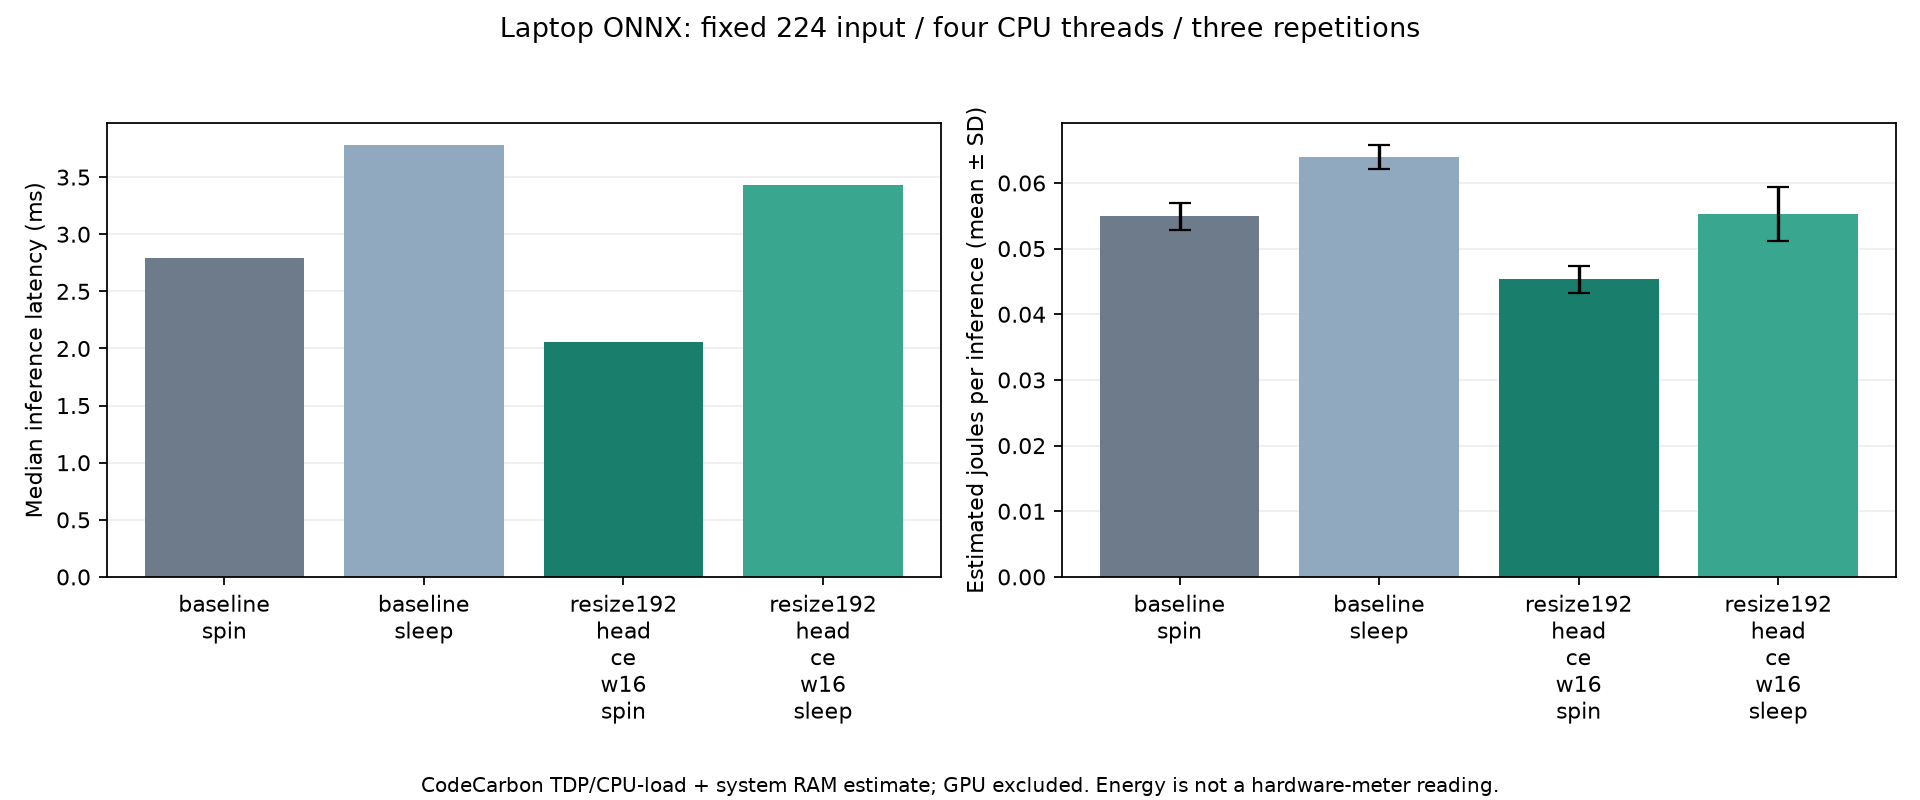

In [13]:
from IPython.display import Image
display(Image(filename=str(project / "results/energy/runtime/tradeoff.png")))